# Swamped: Charting Discrete Data
SDEV2501 · Day 15 · **Student notebook**

The manager of a (fictional) company's IT support desk sends over four weeks of ticket records with one line attached: *"The team feels swamped, and I have budget to add one person. Can you look into it?"*

That's a fair request, but no chart can answer it as it stands. Swamped with what? Swamped compared to when? Which team is feeling it? A big part of the job is turning a vague request like this into specific questions that a chart can answer. We'll ask two:

1. What are people contacting us about? That's a **bar chart**.
2. Which team is under the most pressure? That's a **grouped or stacked bar chart**, and it's where counts and proportions give different answers.

Then we'll make the charts ready to show the manager.

At the end you'll put the answers together into a reply you could send the manager.

The data is in `tickets_sep_oct.csv`, 695 tickets from 14 September to 9 October 2026 (weekdays, 8:00 to 17:00). Every number in it is made up, but the patterns behave like the real thing.

## 0. Setup
Run this cell to import the libraries.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the CSV and take a quick look

Before you chart anything, find out what you've got: how many rows, what the columns are, what's missing, and how the tickets split across the main categories.

Load `tickets_sep_oct.csv` into a DataFrame called `tickets` (turn `created` into real dates). Show its shape and first few rows, count the missing values in each column, and count how many tickets each team has and how many each priority has.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(..., parse_dates=[...])` | Loads the CSV into a DataFrame and turns the listed columns into real dates. |
| `.shape` | The number of rows and columns. It's an attribute, so no brackets. |
| `head()` | Shows the first five rows. |
| `isna().sum()` | `isna()` marks every missing cell, and `sum()` counts them in each column. |
| `value_counts()` | Counts how many rows have each distinct value in a column, biggest first. |

In [2]:
# ---------------------------------------------------------------
# LOAD + SUMMARIZE
# ---------------------------------------------------------------
# parse_dates turns the created text ("2026-09-14 08:42:54") into real datetimes.
tickets = pd.read_csv("tickets_sep_oct.csv", parse_dates=["created"])

# (rows, columns): expect (695, 8)
print(tickets.shape)

# head() returns a DataFrame; display() shows it as a table mid-cell
# (only the LAST line of a cell is displayed automatically).
display(tickets.head())

# isna() is True for every missing cell; sum() adds the Trues up per column.
# Only satisfaction has any: customers who skipped the survey.
display(tickets.isna().sum())

# value_counts() = how many rows per distinct value, biggest first.
display(tickets["team"].value_counts())
tickets["priority"].value_counts()

(695, 8)


,ticket_id,created,team,category,priority,channel,sla_met,satisfaction
0,7001,2026-09-14 08:42:54,Network,VPN,Medium,Chat,Yes,2.0
1,7002,2026-09-14 08:43:10,Service Desk,Hardware,High,Phone,Yes,NaN
2,7003,2026-09-14 08:49:47,Service Desk,Password reset,Low,Portal,Yes,4.0
3,7004,2026-09-14 08:51:39,Service Desk,Software install,Medium,Phone,Yes,3.0
4,7005,2026-09-14 09:05:25,Service Desk,Printing,Medium,Email,Yes,5.0


ticket_id         0
created           0
team              0
category          0
priority          0
channel           0
sla_met           0
satisfaction    218
dtype: int64

team
Service Desk    432
Applications    134
Network         129
Name: count, dtype: int64

priority
Medium      300
Low         228
High        129
Critical     38
Name: count, dtype: int64

Explain these three things about the columns.

1. Which columns are nominal categories (no order), which one is ordinal (ordered categories), and which is just a label?
2. `satisfaction` is stored as the numbers 1 to 5. Explain what kind of data it is, and name one discrete numerical variable (a count) that you could build from this file.
3. Explain what the missing `satisfaction` values are and why they matter for any percentage you calculate.

*Your answer:*

1. `team`, `category`, `channel` and `sla_met` are nominal categories. `priority` is ordinal (Low, Medium, High, Critical). `ticket_id` is a label, and `created` is a timestamp.
2. `satisfaction` is ordinal: 1 to 5 are ordered categories, not measurements. A count I could build is the number of tickets per hour (or per day).
3. 218 tickets have no `satisfaction` because the customer didn't answer the survey. Any percentage should be out of the 477 who answered, not all 695 tickets.

## 2. Question 1: what are people contacting us about?

Ticket `category` is a discrete variable with nine possible values, and the question is *how many tickets are in each?* That's a frequency bar chart: one bar per category, and the bar's length is the count.

Draw a bar chart of the number of tickets in each category, with a title and both axis labels.

| You'll need | What it's for |
|---|---|
| `value_counts()` | Counts the tickets in each category, biggest first. |
| `.plot(kind="bar")` | Draws one bar per row of a Series. pandas draws it with matplotlib, so the `plt.` functions below label the same chart. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. |
| `plt.show()` | Displays the chart. |

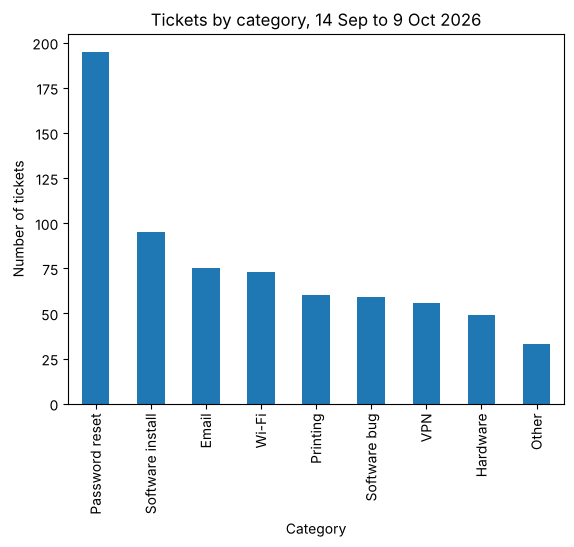

In [3]:
# ---------------------------------------------------------------
# FREQUENCY BAR CHART: tickets per category
# ---------------------------------------------------------------
# value_counts() gives one count per category, biggest first.
category_counts = tickets["category"].value_counts()

# .plot(kind="bar") draws one bar per row. pandas draws it with matplotlib,
# so the plt. functions below label that same chart.
category_counts.plot(kind="bar")

plt.title("Tickets by category, 14 Sep to 9 Oct 2026")
plt.xlabel("Category")
plt.ylabel("Number of tickets")
plt.show()

The manager also wants to know which days are busiest. Weekdays have a natural order, so the bars shouldn't be sorted by size.

Draw a bar chart of the number of tickets on each weekday, in calendar order from Monday to Friday.

| You'll need | What it's for |
|---|---|
| `.dt.day_name()` | Turns each date in a datetime column into its weekday name, such as "Monday". |
| `value_counts()` | Counts the tickets on each weekday, biggest first. |
| `.reindex([...])` | Puts the rows in the order you list instead of biggest first. |
| `.plot(kind="bar")` | Draws one bar per row of a Series. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. |

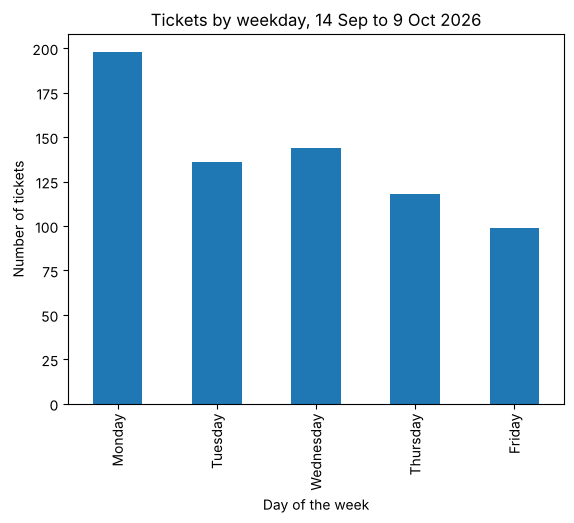

created
Monday       198
Tuesday      136
Wednesday    144
Thursday     118
Friday        99
Name: count, dtype: int64

In [4]:
# ---------------------------------------------------------------
# FREQUENCY BAR CHART: tickets per weekday, in calendar order
# ---------------------------------------------------------------
# The order we want. value_counts() on its own would sort by size.
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

# .dt.day_name() turns each datetime into its weekday name ("Monday", ...).
# reindex() then puts the counts in the order we listed.
weekday_counts = tickets["created"].dt.day_name().value_counts().reindex(weekday_order)

weekday_counts.plot(kind="bar")
plt.title("Tickets by weekday, 14 Sep to 9 Oct 2026")
plt.xlabel("Day of the week")
plt.ylabel("Number of tickets")
plt.show()

# The exact counts behind the bars.
weekday_counts

Explain why the weekday chart is in calendar order while the category chart is biggest first, and why both are bar charts and not histograms.

*Your answer:*

Weekdays have a natural order, so the bars stay Monday to Friday. Categories have no order, so sorting them by size makes the biggest easy to find. Both are bar charts because each bar is one distinct value, so the bars are separated. A histogram splits a continuous number into ranges of values, and its bars touch.

## 3. Question 2: which team is under the most pressure?

Pressure is about how urgent the tickets are, so we'll look at priority by team. That's two categorical variables, which a grouped or stacked bar chart handles: one group (or one stack) per team, and one bar (or one segment) per priority.

Count the tickets for each team and priority, with the priorities in order from Low to Critical, and show the table. Then draw a grouped bar chart of the counts.

| You'll need | What it's for |
|---|---|
| `pd.crosstab(a, b)` | Counts the rows for every pair of values: one row per value of `a`, one column per value of `b`. |
| `[[...]]` with a list of column names | Picks columns and puts them in the order you list. Here, the priorities from Low to Critical. |
| `.plot(kind="bar")` | On a DataFrame, draws one group of bars per row and one bar per column. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. |

priority,Low,Medium,High,Critical
team,,,,
Applications,33,58,32,11
Network,21,61,37,10
Service Desk,174,181,60,17


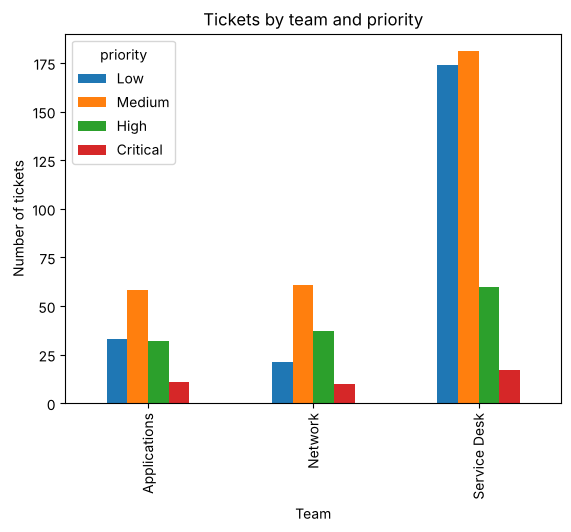

In [5]:
# ---------------------------------------------------------------
# GROUPED BAR CHART: priority by team (counts)
# ---------------------------------------------------------------
# Least to most urgent. crosstab would sort the columns alphabetically.
priority_order = ["Low", "Medium", "High", "Critical"]

# crosstab: one row per team, one column per priority,
# each cell = the number of tickets with that team AND that priority.
# [priority_order] re-orders the columns.
by_team = pd.crosstab(tickets["team"], tickets["priority"])[priority_order]
display(by_team)

# On a DataFrame, .plot(kind="bar") draws one GROUP of bars per row (team),
# with one bar per column (priority).
by_team.plot(kind="bar")

plt.title("Tickets by team and priority")
plt.xlabel("Team")
plt.ylabel("Number of tickets")
plt.show()

Draw the same counts as a stacked bar chart.

| You'll need | What it's for |
|---|---|
| `.plot(kind="bar", stacked=True)` | Stacks each row's bars on top of each other, so each team's bar is as tall as the team's total. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. |

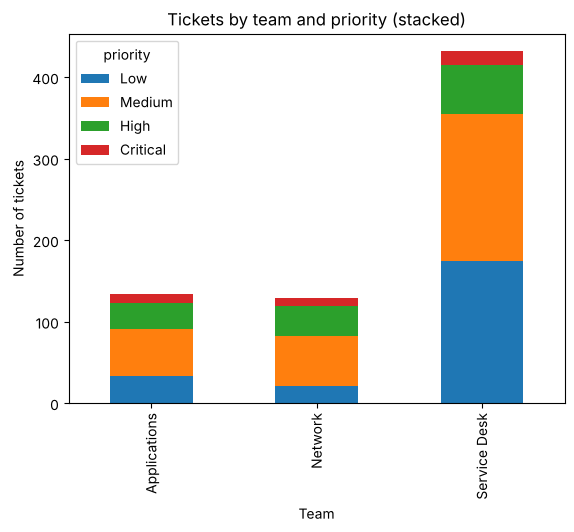

In [6]:
# ---------------------------------------------------------------
# STACKED BAR CHART: same counts
# ---------------------------------------------------------------
# stacked=True piles each row's bars into one tall bar.
# The bar's total height is the team's total number of tickets.
by_team.plot(kind="bar", stacked=True)

plt.title("Tickets by team and priority (stacked)")
plt.xlabel("Team")
plt.ylabel("Number of tickets")
plt.show()

Explain which team has the most tickets overall and which team has the most High and Critical tickets. Then explain what the stacked chart shows more easily than the grouped chart, and what the grouped chart shows more easily.

*Your answer:*

Service Desk has the most tickets overall (432) and the most High and Critical tickets (60 High plus 17 Critical, 77 in total). The stacked chart shows each team's total at a glance. The grouped chart is better for comparing one priority across teams, because every bar starts at zero.

The Service Desk dominates every priority because it handles far more tickets. To compare the teams fairly, convert each team's counts into percentages of that team's own total, and draw a 100% stacked bar chart.

| You'll need | What it's for |
|---|---|
| `pd.crosstab(a, b, normalize="index")` | The same count table, but each row is divided by its own total, so every team's row adds up to 1. |
| `* 100` | Turns fractions into percentages. |
| `.plot(kind="bar", stacked=True)` | Stacks each row's bars into one bar. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. Put the units in the y label. |

priority,Low,Medium,High,Critical
team,,,,
Applications,24.6,43.3,23.9,8.2
Network,16.3,47.3,28.7,7.8
Service Desk,40.3,41.9,13.9,3.9


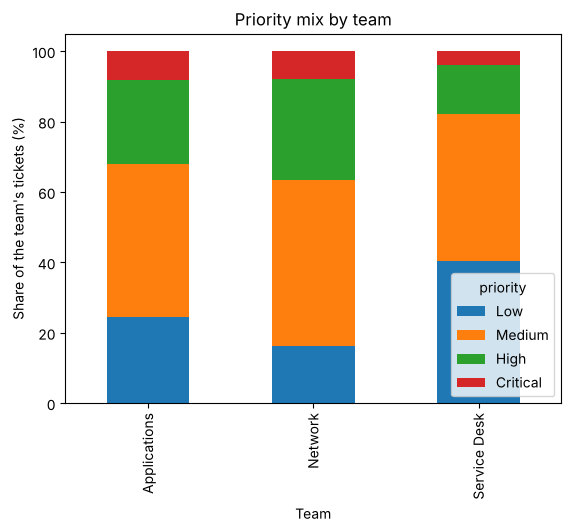

In [7]:
# ---------------------------------------------------------------
# 100% STACKED BAR CHART: priority mix inside each team
# ---------------------------------------------------------------
# normalize="index" divides every row by that row's total,
# so each team's row adds up to 1. Multiply by 100 for percentages.
by_team_pct = pd.crosstab(tickets["team"], tickets["priority"], normalize="index")[priority_order] * 100
display(by_team_pct.round(1))

by_team_pct.plot(kind="bar", stacked=True)
plt.title("Priority mix by team")
plt.xlabel("Team")
plt.ylabel("Share of the team's tickets (%)")
plt.show()

Work out how many High or Critical tickets each team has, how many tickets each team has in total, and the percentage of each team's tickets that are High or Critical. Show the three results side by side in one table.

| You'll need | What it's for |
|---|---|
| `[["High", "Critical"]].sum(axis=1)` | Picks two columns and adds them together for each row (each team). `axis=1` means across the columns. |
| `.sum(axis=1)` | Adds all the columns in each row, which is the team's total tickets. |
| `/` and `* 100` | Divide the count by the total, then turn the fraction into a percentage. |
| `pd.DataFrame({...})` | Builds a table from a dictionary: each key becomes a column name. |
| `round(1)` | Rounds every value to 1 decimal place. |

In [8]:
# ---------------------------------------------------------------
# COUNTS VS PROPORTIONS
# ---------------------------------------------------------------
# Add the High and Critical columns for each team (axis=1 = across columns).
high_or_critical = by_team[["High", "Critical"]].sum(axis=1)

# Add ALL the columns for each team = the team's total tickets.
team_total = by_team.sum(axis=1)

# Three Series side by side in one table. The percentage is
# "High or Critical tickets" out of "this team's own tickets".
summary = pd.DataFrame({
    "high_or_critical": high_or_critical,
    "total_tickets": team_total,
    "pct_high_or_critical": (high_or_critical / team_total * 100).round(1),
})
summary

,high_or_critical,total_tickets,pct_high_or_critical
team,,,
Applications,43,134,32.1
Network,47,129,36.4
Service Desk,77,432,17.8


Explain which team has the bigger problem with High and Critical tickets. Answer once using counts and once using percentages, and say what the denominator is each time.

*Your answer:*

By count, Service Desk has the biggest problem: 77 High or Critical tickets, against 47 for Network and 43 for Applications. The denominator there is all tickets, so it mostly reflects how many tickets Service Desk handles. By percentage, Network has the biggest problem: 36.4% of its 129 tickets are High or Critical, against 32.1% of Applications' 134 and 17.8% of Service Desk's 432. The denominator there is each team's own tickets.

## 4. Make it presentable: colour, labels, units

The charts so far are readable but not ready to show the manager. The category labels are vertical, nothing says which category matters, the legend covers part of the 100% chart and the titles only name the topic.

Redraw the category bar chart from §2 with horizontal bars, the biggest at the top, one colour for the biggest category and light grey for the rest, the count printed on each bar, a title that states the finding and axis labels that say what is counted.

| You'll need | What it's for |
|---|---|
| `sort_values()` | Sorts a Series from smallest to largest. A horizontal bar chart draws its first bar at the bottom, so this puts the biggest bar on top. |
| a list of colours | One colour per bar, in the same order as the bars. Here, light grey for every bar except the biggest. |
| `plt.barh(..., color=...)` | Draws horizontal bars, one per label. `color` can be a list with one colour per bar. |
| `plt.bar_label(...)` | Prints each bar's value at its end. Give it the bars that `plt.barh()` returned. |
| `plt.figure(figsize=...)` | Starts a new chart at a set size in inches (width, height). Call it before you draw. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels, with the units. |

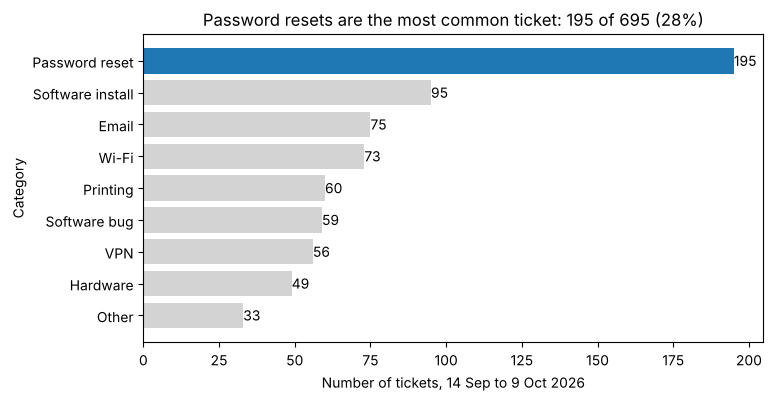

In [9]:
# ---------------------------------------------------------------
# BEST PRACTICES 1: the category chart, ready to show
# ---------------------------------------------------------------
# value_counts() is biggest-first; sort_values() flips it to smallest-first.
# barh draws its first bar at the BOTTOM, so the biggest ends up on top.
counts = tickets["category"].value_counts().sort_values()

# One colour per bar: light grey for all but the last (biggest) bar, which gets a colour.
colors = ["lightgrey"] * (len(counts) - 1) + ["tab:blue"]

plt.figure(figsize=(8, 4))

# barh returns the bars it drew; bar_label needs them to print each value.
bars = plt.barh(counts.index, counts.values, color=colors)
plt.bar_label(bars)

# The title says what to conclude, not just what the chart is about.
plt.title(f"Password resets are the most common ticket: {counts.max()} of {counts.sum()} ({counts.max() / counts.sum() * 100:.0f}%)")
plt.xlabel("Number of tickets, 14 Sep to 9 Oct 2026")
plt.ylabel("Category")
plt.show()

Redraw the 100% stacked chart from §3 with colours that follow the order of the priorities (light for Low, dark for Critical), a legend that doesn't cover the bars, a title that states the finding and axis labels with units.

| You'll need | What it's for |
|---|---|
| `.plot(..., colormap=...)` | Picks the bar colours from a matplotlib palette. A sequential palette such as `"Oranges"` runs from light to dark, which suits ordered categories. |
| `plt.legend(..., loc=..., bbox_to_anchor=...)` | Places the legend. `bbox_to_anchor=(1, 1)` is the chart's top-right corner, and `loc="upper left"` hangs the legend off that corner, outside the bars. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels, with the units. |

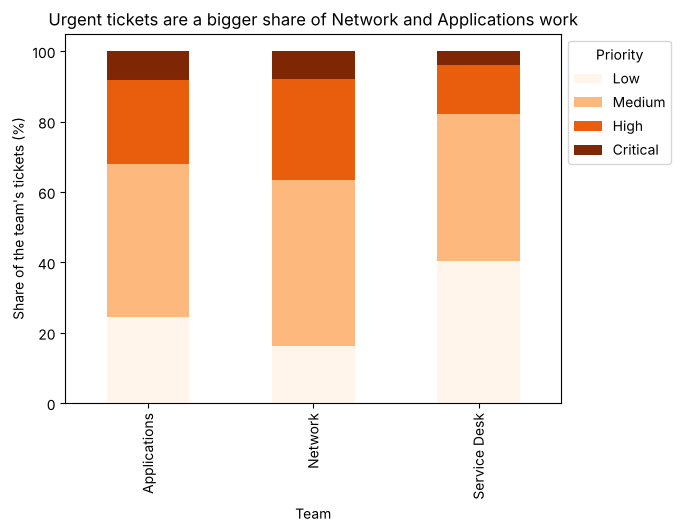

In [10]:
# ---------------------------------------------------------------
# BEST PRACTICES 2: the priority mix, with colours that follow the order
# ---------------------------------------------------------------
# colormap="Oranges" is a SEQUENTIAL palette: light -> dark.
# The priorities are ordered (Low -> Critical), so the colours should be too.
by_team_pct.plot(kind="bar", stacked=True, colormap="Oranges")

# bbox_to_anchor=(1, 1) = the chart's top-right corner.
# loc="upper left" hangs the legend off that corner, outside the bars.
plt.legend(title="Priority", loc="upper left", bbox_to_anchor=(1, 1))

plt.title("Urgent tickets are a bigger share of Network and Applications work")
plt.xlabel("Team")
plt.ylabel("Share of the team's tickets (%)")
plt.show()

Explain which of your changes made the biggest difference to how quickly the manager can read the category chart. Then explain why the two charts use colour in different ways.

*Your answer:*

Sorting the bars and highlighting only the biggest one made the biggest difference, because the reader sees straight away that password resets are the biggest category. The category chart uses grey plus one colour because only one bar carries the message. The priority chart uses a light-to-dark palette because the priorities are ordered, and neither chart uses a different colour for every bar.

## 5. What each chart can't tell you

Every chart hides something. Fill in the last column from what you saw today.

| Chart | Question it answered | What it hides or gets wrong |
|---|---|---|
| Bar chart | What are people contacting us about? | Counts tell you how many but not why. It doesn't show what share of anything the counts are. The order and colours change what you notice first. |
| Grouped or stacked bar chart | Which team is under the most pressure? | Counts favour the biggest group: Service Desk has the most High tickets because it has the most tickets. In a stack only the bottom segment starts at zero, so the others are hard to compare. A 100% stack hides the team sizes (432, 134 and 129). |

## 6. Back to the manager
The manager asked a vague request: *"The team feels swamped, and I have budget to add one person. Can you look into it?"* You've now answered two specific questions.

Explain, in four or five sentences you could send the manager, where the swamped feeling comes from and where the extra person should go. Use numbers from your charts, say what each percentage is a percentage of, and keep it in plain language: the manager doesn't know what a crosstab is.

*Your answer:*

Most of the work lands on the Service Desk: it handles 432 of 695 tickets (62%) and has 77 of the High and Critical ones. But Network and Applications have the most urgent tickets for their size: 36.4% of Network's tickets and 32.1% of Applications' are High or Critical, against 17.8% for the Service Desk. Password resets are 28% of all tickets (195), so fixing those might free up more time than one hire. Mondays are the busiest day with 198 tickets, double Friday's 99. I'd put the new person on the Service Desk if the goal is volume, or on Network if the goal is urgent tickets.

## 7. Want more practice? (optional)
The manager liked the answer and comes back with another vague request: *"Are our customers happy, and are we keeping up with demand?"* Turn it into two specific questions and answer each with a bar chart: one frequency bar chart and one grouped or stacked bar chart.

Here are some questions to start from, or write your own:
- *How satisfied are customers?* (`satisfaction` is ordinal, and some customers didn't answer, so decide what your percentages are out of.)
- *Which team misses its SLA most often?* (`sla_met` is Yes or No for each ticket, and the teams are different sizes.)
- *Which channel do people use to contact us?*
- *Does the mix of priorities change by weekday?*

For each chart, write the question as a Markdown heading first, then the code, then one sentence on what the chart shows. Use what you did today: bars in a meaningful order, units on the axes, a title that states the finding, and colour only where it has a job.

### Question 1: how satisfied are customers?

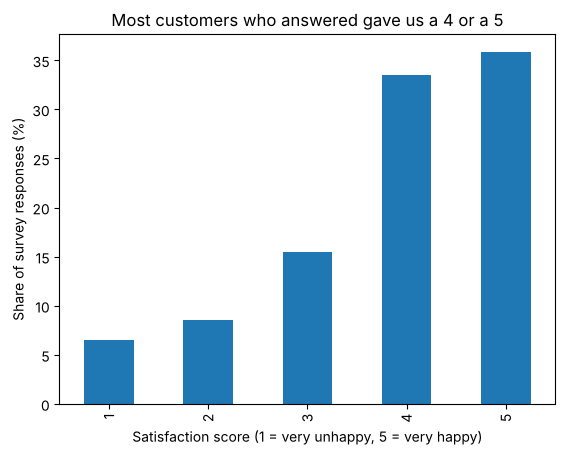

answered: 477   did not answer: 218
share rating 4 or 5: 69 %


In [11]:
# ---------------------------------------------------------------
# PRACTICE 1 (ordinal): how satisfied are customers?
# ---------------------------------------------------------------
# dropna() removes the customers who didn't answer; astype(int) turns 4.0 into 4.
# sort_index() puts the scores in order 1 to 5.
ratings = tickets["satisfaction"].dropna().astype(int).value_counts().sort_index()

# Percentage of the people who ANSWERED (the denominator), not of all tickets.
(ratings / ratings.sum() * 100).plot(kind="bar", color="tab:blue")
plt.title("Most customers who answered gave us a 4 or a 5")
plt.xlabel("Satisfaction score (1 = very unhappy, 5 = very happy)")
plt.ylabel("Share of survey responses (%)")
plt.show()

print("answered:", ratings.sum(), "  did not answer:", tickets["satisfaction"].isna().sum())
print("share rating 4 or 5:", round((ratings[4] + ratings[5]) / ratings.sum() * 100), "%")

69% of the customers who answered gave us a 4 or a 5 (331 of 477), and 218 customers didn't answer.

### Question 2: which team misses its SLA most often?

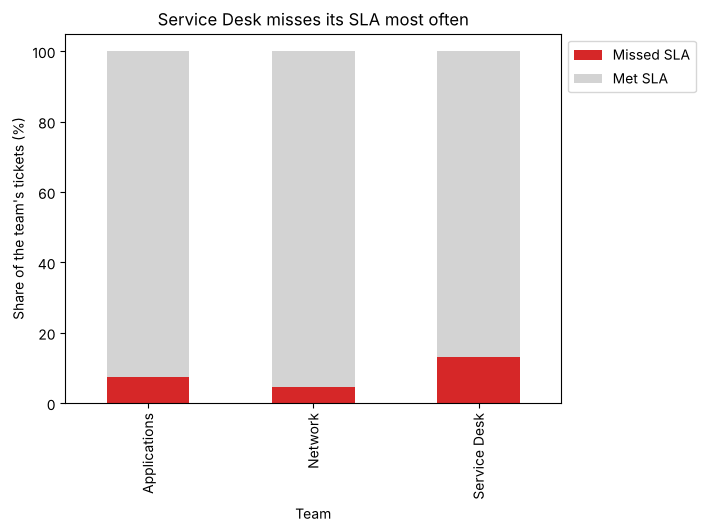

sla_met         No   Yes
team                    
Applications   7.5  92.5
Network        4.7  95.3
Service Desk  13.2  86.8


In [12]:
# ---------------------------------------------------------------
# PRACTICE 2 (100% stacked): which team misses its SLA most often?
# ---------------------------------------------------------------
# The teams are different sizes, so compare SHARES: normalize="index" makes each row add up to 1.
sla = pd.crosstab(tickets["team"], tickets["sla_met"], normalize="index") * 100

# Missed first (bottom of the stack, so it starts at zero and is easy to compare), then met.
sla[["No", "Yes"]].plot(kind="bar", stacked=True, color=["tab:red", "lightgrey"])
plt.legend(["Missed SLA", "Met SLA"], loc="upper left", bbox_to_anchor=(1, 1))
plt.title("Service Desk misses its SLA most often")
plt.xlabel("Team")
plt.ylabel("Share of the team's tickets (%)")
plt.show()

print(sla.round(1))

The Service Desk missed its SLA on 13.2% of its tickets, against 7.5% for Applications and 4.7% for Network.